In [1]:
print("hi")

hi


In [2]:
import pandas as pd
import seaborn as sns

df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


##NULL HANDLING

In [3]:
# Count nulls per column (only show columns that have nulls)
null_counts = df.isnull().sum()
print(null_counts[null_counts > 0])

# Overall summary
print("\nTotal null values:", df.isnull().sum().sum())
print("Columns with nulls:", (null_counts > 0).sum())

Series([], dtype: int64)

Total null values: 0
Columns with nulls: 0


In [8]:
# Convert text to numbers; blanks (" ") can't be converted, so they become NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Verify the new dtype and the blanks that are now real nulls
print(df["TotalCharges"].dtype)
print("Null TotalCharges:", df["TotalCharges"].isnull().sum())

float64
Null TotalCharges: 11


In [9]:
# Drop the 11 rows with missing TotalCharges
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)

# Verify
print("Shape after drop:", df.shape)
print("Remaining nulls:", df.isnull().sum().sum())

Shape after drop: (7032, 21)
Remaining nulls: 0


##outlayer handling

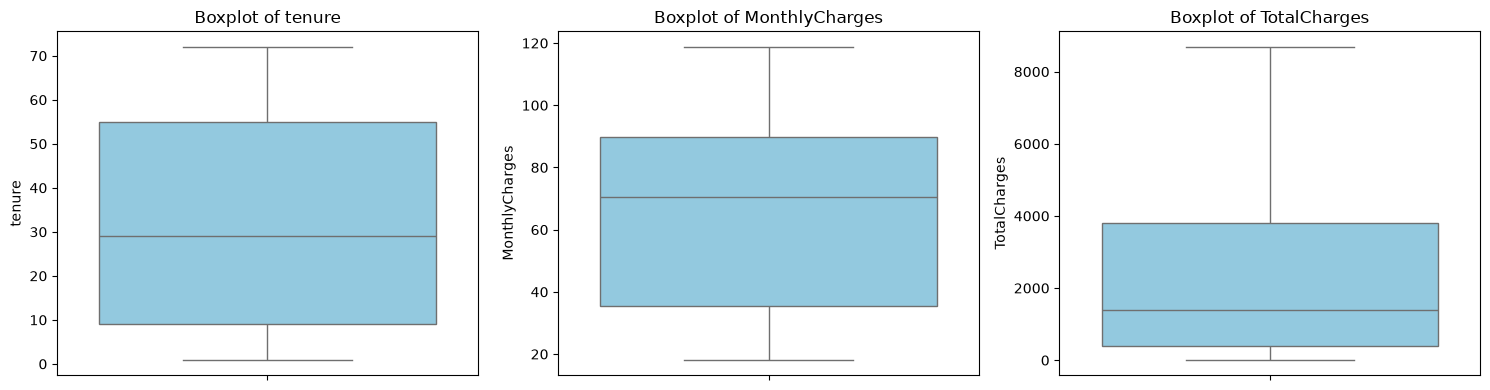

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="skyblue")
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

convert the Yes/No columns to 0/1

In [11]:
# Columns that contain only "Yes" / "No"
yes_no_cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]

for col in yes_no_cols:
    df[col] = df[col].map({"Yes": 1, "No": 0})

# Verify: dtypes should be int64 and values only 0/1
print(df[yes_no_cols].dtypes)
print(df[yes_no_cols].nunique())
print("Nulls:", df[yes_no_cols].isnull().sum().sum())

Partner             int64
Dependents          int64
PhoneService        int64
PaperlessBilling    int64
Churn               int64
dtype: object
Partner             2
Dependents          2
PhoneService        2
PaperlessBilling    2
Churn               2
dtype: int64
Nulls: 0


other catocorical unique value 

In [12]:
# Remaining text columns (everything still stored as text, except the ID)
cat_cols = df.select_dtypes(include=["object", "string"]).columns.drop("customerID")

for col in cat_cols:
    print(f"{col}: {df[col].nunique()} unique -> {df[col].unique().tolist()}")
    print(df[col].value_counts().to_string(), "\n")

gender: 2 unique -> ['Female', 'Male']
gender
Male      3549
Female    3483 

MultipleLines: 3 unique -> ['No phone service', 'No', 'Yes']
MultipleLines
No                  3385
Yes                 2967
No phone service     680 

InternetService: 3 unique -> ['DSL', 'Fiber optic', 'No']
InternetService
Fiber optic    3096
DSL            2416
No             1520 

OnlineSecurity: 3 unique -> ['No', 'Yes', 'No internet service']
OnlineSecurity
No                     3497
Yes                    2015
No internet service    1520 

OnlineBackup: 3 unique -> ['Yes', 'No', 'No internet service']
OnlineBackup
No                     3087
Yes                    2425
No internet service    1520 

DeviceProtection: 3 unique -> ['No', 'Yes', 'No internet service']
DeviceProtection
No                     3094
Yes                    2418
No internet service    1520 

TechSupport: 3 unique -> ['No', 'Yes', 'No internet service']
TechSupport
No                     3472
Yes                    2040
No int

In [13]:
service_cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]

for col in service_cols:
    df[col] = df[col].replace({"No phone service": "No", "No internet service": "No"})
    df[col] = df[col].map({"Yes": 1, "No": 0})

# Verify
print(df[service_cols].dtypes)
print(df[service_cols].nunique())
print("Nulls:", df[service_cols].isnull().sum().sum())

MultipleLines       int64
OnlineSecurity      int64
OnlineBackup        int64
DeviceProtection    int64
TechSupport         int64
StreamingTV         int64
StreamingMovies     int64
dtype: object
MultipleLines       2
OnlineSecurity      2
OnlineBackup        2
DeviceProtection    2
TechSupport         2
StreamingTV         2
StreamingMovies     2
dtype: int64
Nulls: 0


In [14]:
remaining = df.select_dtypes(exclude="number").columns.drop("customerID")

for col in remaining:
    print(f"{col}: {df[col].nunique()} unique -> {df[col].unique().tolist()}")

gender: 2 unique -> ['Female', 'Male']
InternetService: 3 unique -> ['DSL', 'Fiber optic', 'No']
Contract: 3 unique -> ['Month-to-month', 'One year', 'Two year']
PaymentMethod: 4 unique -> ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']


In [15]:
df["gender"] = df["gender"].map({"Female": 0, "Male": 1})

print(df["gender"].value_counts())
print("Nulls:", df["gender"].isnull().sum())

gender
1    3549
0    3483
Name: count, dtype: int64
Nulls: 0


one hot encode 

In [16]:
df = pd.get_dummies(
    df,
    columns=["InternetService", "Contract", "PaymentMethod"],
    drop_first=True,   # drops one column per feature to avoid redundancy
    dtype=int          # 0/1 integers instead of True/False
)

# Verify
print("Shape:", df.shape)
print(df.columns.tolist())
print(df.dtypes.value_counts())

Shape: (7032, 25)
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']
int64      22
float64     2
str         1
Name: count, dtype: int64


## Feature selection 

In [17]:


# Drop the ID column (identifier, not a predictive feature)
df = df.drop(columns="customerID", errors="ignore")

# Verify
print("customerID still present:", "customerID" in df.columns)
print("Shape:", df.shape)
print("Non-numeric columns:", df.select_dtypes(exclude="number").columns.tolist())

customerID still present: False
Shape: (7032, 24)
Non-numeric columns: []


corelation_code 

tenure                                  -0.354
Contract_Two year                       -0.302
InternetService_No                      -0.228
TotalCharges                            -0.199
Contract_One year                       -0.178
OnlineSecurity                          -0.171
TechSupport                             -0.165
Dependents                              -0.163
Partner                                 -0.150
PaymentMethod_Credit card (automatic)   -0.135
PaymentMethod_Mailed check              -0.091
OnlineBackup                            -0.082
DeviceProtection                        -0.066
gender                                  -0.009
PhoneService                             0.012
MultipleLines                            0.040
StreamingMovies                          0.061
StreamingTV                              0.063
SeniorCitizen                            0.151
PaperlessBilling                         0.191
MonthlyCharges                           0.193
PaymentMethod

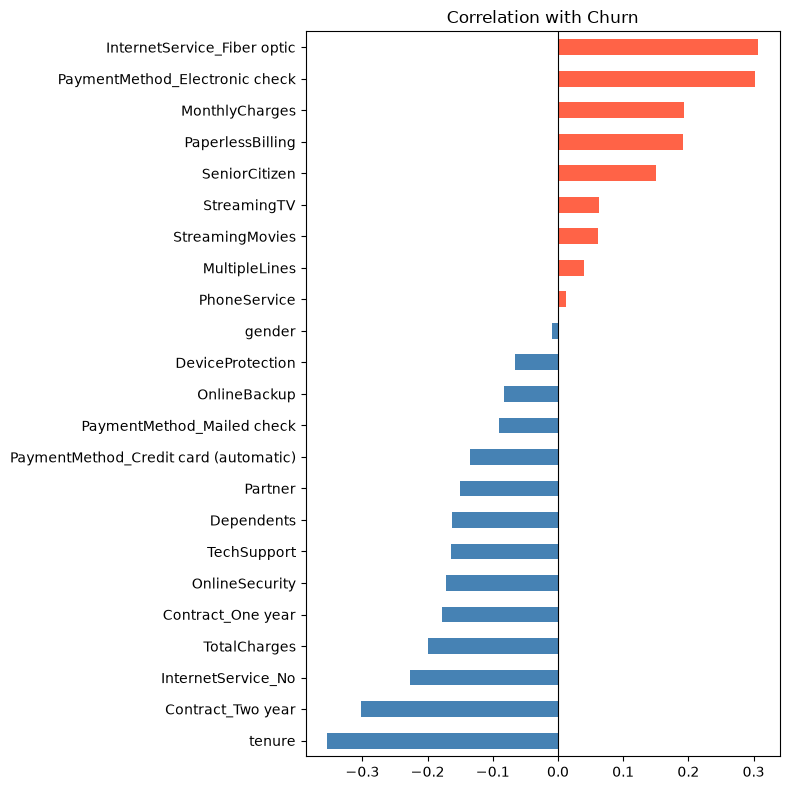

In [18]:
import matplotlib.pyplot as plt

# Correlation of each feature with Churn, sorted by strength
corr = df.corr()["Churn"].drop("Churn").sort_values()

print(corr.round(3).to_string())

# Bar plot
plt.figure(figsize=(8, 8))
corr.plot(kind="barh", color=["tomato" if v > 0 else "steelblue" for v in corr])
plt.title("Correlation with Churn")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

In [21]:
threshold = 0.07  # keep features with |correlation| above this

selected = corr[corr.abs() > threshold].index.tolist()
dropped = corr[corr.abs() <= threshold].index.tolist()

print(f"Keeping {len(selected)} features:\n", selected)
print(f"\nDropping {len(dropped)} weak features:\n", dropped)

Keeping 17 features:
 ['tenure', 'Contract_Two year', 'InternetService_No', 'TotalCharges', 'Contract_One year', 'OnlineSecurity', 'TechSupport', 'Dependents', 'Partner', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Mailed check', 'OnlineBackup', 'SeniorCitizen', 'PaperlessBilling', 'MonthlyCharges', 'PaymentMethod_Electronic check', 'InternetService_Fiber optic']

Dropping 6 weak features:
 ['DeviceProtection', 'gender', 'PhoneService', 'MultipleLines', 'StreamingMovies', 'StreamingTV']


data splitting

In [22]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="Churn")
# X = df[selected]   # use this line instead if you want only the correlation-selected features

y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,        # keeps the ~26% churn ratio in both sets
    random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train:", round(y_train.mean(), 3))
print("Churn rate test:", round(y_test.mean(), 3))

Train: (5625, 23) | Test: (1407, 23)
Churn rate train: 0.266
Churn rate test: 0.266


In [27]:
import os



# Full cleaned dataset
df.to_csv("../data/processed/churn_clean.csv", index=False)

# Train/test splits (features + target together)
train_out = X_train.copy()
train_out["Churn"] = y_train
test_out = X_test.copy()
test_out["Churn"] = y_test

train_out.to_csv("../data/processed/train.csv", index=False)
test_out.to_csv("../data/processed/test.csv", index=False)

print(os.listdir("../data/processed"))

['churn_clean.csv', 'clean.csv', 'test.csv', 'train.csv']


       count  percent
Churn                
0       4130     73.4
1       1495     26.6


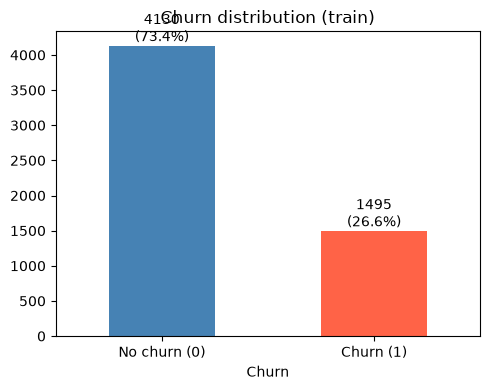

In [28]:
import matplotlib.pyplot as plt

counts = y_train.value_counts().sort_index()
pct = (counts / counts.sum() * 100).round(1)

print(pd.DataFrame({"count": counts, "percent": pct}))

plt.figure(figsize=(5, 4))
ax = counts.plot(kind="bar", color=["steelblue", "tomato"])
ax.set_xticklabels(["No churn (0)", "Churn (1)"], rotation=0)
ax.set_title("Churn distribution (train)")
for i, (c, p) in enumerate(zip(counts, pct)):
    ax.text(i, c, f"{c}\n({p}%)", ha="center", va="bottom")
plt.tight_layout()
plt.show()

SeniorCitizen                            16.2
Contract_One year                        21.0
InternetService_No                       21.5
PaymentMethod_Credit card (automatic)    21.6
PaymentMethod_Mailed check               22.5
Contract_Two year                        24.1
OnlineSecurity                           28.7
TechSupport                              29.5
Dependents                               30.0
PaymentMethod_Electronic check           33.9
DeviceProtection                         34.6
OnlineBackup                             35.0
StreamingTV                              38.9
StreamingMovies                          39.0
MultipleLines                            42.4
InternetService_Fiber optic              44.1
Partner                                  48.6
gender                                   50.2
PaperlessBilling                         59.5
PhoneService                             90.3


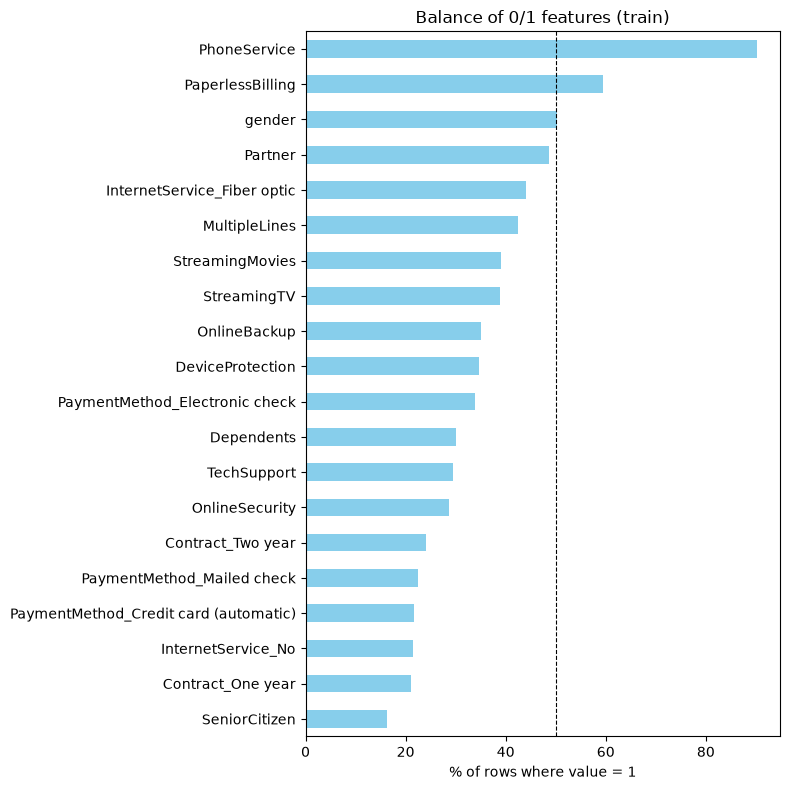

In [29]:
# All columns with exactly two values (0/1 features)
bin_cols = [c for c in X_train.columns if X_train[c].nunique() == 2]

# Percent of rows where each feature = 1
bal = (X_train[bin_cols].mean() * 100).round(1).sort_values()

print(bal.to_string())

plt.figure(figsize=(8, 8))
bal.plot(kind="barh", color="skyblue")
plt.axvline(50, color="black", linestyle="--", linewidth=0.8)
plt.xlabel("% of rows where value = 1")
plt.title("Balance of 0/1 features (train)")
plt.tight_layout()
plt.show()

NameError: name 'X_train_s' is not defined